[Sommaire](00_sommaire.ipynb) · ⬅ [Thème 2 — Matrices](theme2_matrices_simulation.ipynb) · [Thème 4 — Pile](theme4_pile.ipynb) ➡

# Thème 3 — Fenêtre glissante (sliding window) et deux pointeurs (two pointers)

**Dans ce notebook, tu vas apprendre :**
- ce que veut dire « contigu » ;
- faire glisser une fenêtre de taille fixe, puis de taille variable (la « chenille ») ;
- utiliser deux pointeurs qui se rapprochent sur une liste triée ;
- pourquoi ces techniques sont en O(n) malgré une boucle dans une boucle.

**Prérequis :** thèmes 0 et 1 (notation O, set, dict)

> Exécute d'abord la cellule ci-dessous : elle contient l'outil `verifier`, qui teste automatiquement ta solution dans l'exercice final.

In [ ]:
# Outil utilisé dans l'exercice « À toi de jouer » de ce notebook.
# Il appelle ta fonction sur plusieurs cas et affiche ✅ (bon), ❌ (mauvais) ou 💥 (plantage).
# Tu n'as pas besoin de comprendre ce code pour t'en servir : exécute simplement cette cellule.

import copy

def verifier(fonction, cas):
    reussis = 0
    for arguments, attendu in cas:
        texte_args = ", ".join(repr(a) for a in arguments)
        try:
            obtenu = fonction(*copy.deepcopy(arguments))
        except Exception as erreur:
            print(f"💥 {fonction.__name__}({texte_args}) a planté : {type(erreur).__name__}: {erreur}")
            continue
        if obtenu == attendu:
            reussis += 1
            print(f"✅ {fonction.__name__}({texte_args}) -> {obtenu!r}")
        else:
            print(f"❌ {fonction.__name__}({texte_args}) -> {obtenu!r}   (attendu : {attendu!r})")
    print(f"\n{reussis}/{len(cas)} tests réussis")

## Le vocabulaire d'abord : « contigu »
Une portion **contiguë**, ce sont des éléments **qui se suivent, sans trou**.
Dans `[5, 2, 8, 1]` :
- `[2, 8, 1]` est un **sous-tableau** (contigu) ✅
- `[5, 8]` **n'est pas** contigu (on a sauté le 2) ❌

Pareil pour les chaînes : dans `"abcabcbb"`, `"cab"` est une **sous-chaîne** ; `"acb"` (obtenu en sautant des lettres) n'en est pas une.

Les deux techniques de ce thème évitent de **tester toutes les portions possibles** (ce qui coûte O(n²) ou plus).

## Partie 1 — Fenêtre de taille fixe : l'idée de base

### Le problème de départ
> Dans `[2, 1, 5, 1, 3, 2]`, quelle est la plus grande somme de **3 éléments consécutifs** ?

**Approche naïve** : pour chaque début possible, additionner les 3 éléments.
`2+1+5 = 8`, `1+5+1 = 7`, `5+1+3 = 9`, `1+3+2 = 6` → maximum = 9.

Remarque : d'une portion à la suivante, **deux éléments sur trois sont les mêmes**. On refait des additions déjà faites. Avec une portion de taille `k` dans une liste de taille `n`, ça coûte environ `n × k` opérations.

### Le concept : faire glisser un cadre
Imagine un cadre posé sur 3 cases. Pour le décaler d'un cran vers la droite :
- une case **sort** à gauche → on la **retire** de la somme ;
- une case **entre** à droite → on l'**ajoute**.

**Nouvelle somme = ancienne somme − élément qui sort + élément qui entre.** Deux opérations au lieu de `k`.
```
[2, 1, 5] 1, 3, 2     somme = 8
 2,[1, 5, 1] 3, 2     somme = 8 - 2 + 1 = 7
 2, 1,[5, 1, 3] 2     somme = 7 - 1 + 3 = 9   ← maximum
 2, 1, 5,[1, 3, 2]    somme = 9 - 5 + 2 = 6
```

In [ ]:
def somme_max_fenetre(nombres, k):
    if k <= 0 or k > len(nombres):
        return None

    somme = sum(nombres[:k])            # la toute première fenêtre : indices 0 à k-1
    meilleure = somme

    for fin in range(k, len(nombres)):  # fin = indice de l'élément qui ENTRE
        somme += nombres[fin]           # il entre par la droite
        somme -= nombres[fin - k]       # celui situé k cases plus à gauche SORT
        meilleure = max(meilleure, somme)

    return meilleure

print(somme_max_fenetre([2, 1, 5, 1, 3, 2], 3))   # 9

Pourquoi `fin - k` ? Après l'entrée de `nombres[fin]`, la fenêtre doit couvrir les indices `fin-k+1` à `fin` (soit k éléments). L'élément juste avant, d'indice `fin - k`, doit donc sortir.

Chaque élément entre une fois et sort une fois → **O(n)**, quelle que soit la valeur de `k`.

## Partie 2 — Fenêtre de taille variable : la chenille

### Le problème de départ
> Quelle est la longueur de la plus longue sous-chaîne **sans caractère répété** ?
> `"abcabcbb"` → 3 (`"abc"`).

Cette fois, la taille de la fenêtre n'est pas imposée. On utilise **deux indices** :
- `fin` : le bord droit. Il avance **toujours** d'une case à chaque tour (on essaie d'agrandir la fenêtre) ;
- `debut` : le bord gauche. Il avance **seulement quand la fenêtre devient invalide** (ici : quand elle contient un doublon), jusqu'à ce qu'elle redevienne valide.

**Image mentale : une chenille.** La tête avance à chaque pas ; quand le corps devient « invalide », la queue se rapproche.

À tout moment, la fenêtre `texte[debut : fin + 1]` est valide, et sa longueur vaut **`fin - debut + 1`**. Le `+ 1` vient du fait que les deux bords sont **inclus** : de l'indice 2 à l'indice 4, il y a 3 cases (2, 3, 4), pas 2.

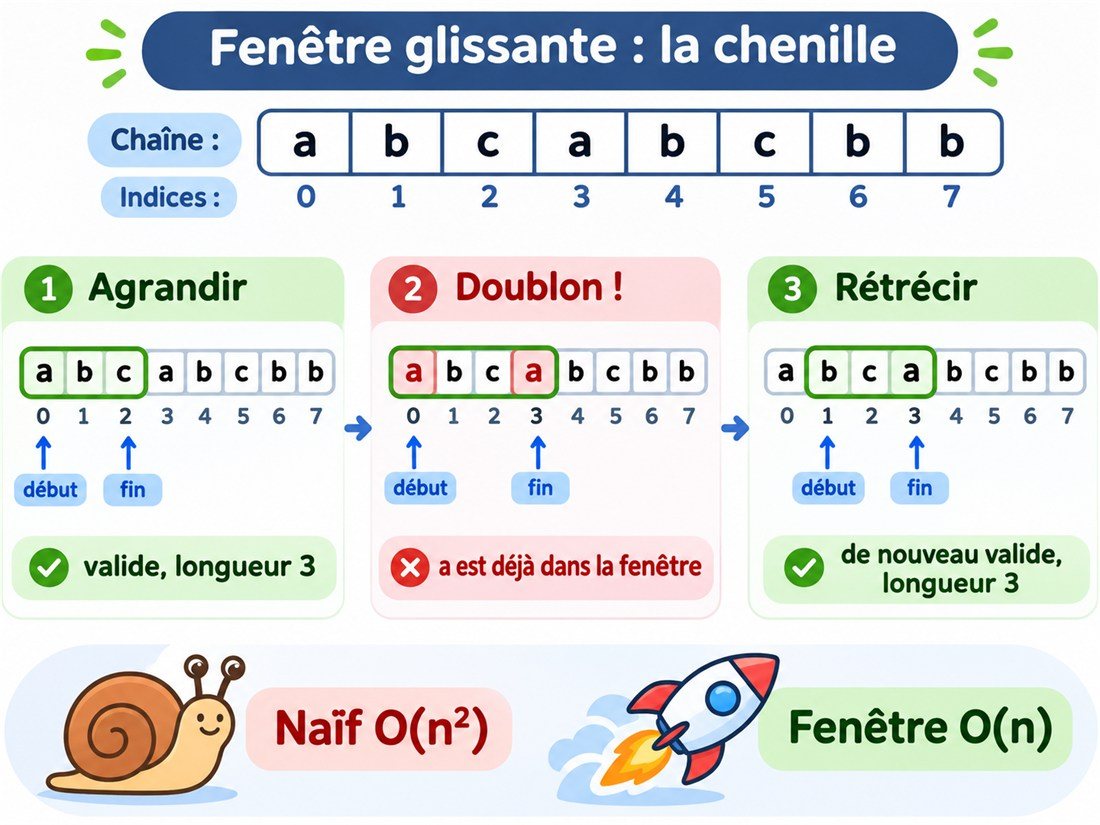

Sur l'image, en trois temps : ① la fenêtre `"abc"` (indices 0 à 2) est valide ; ② la fin avance sur le `a` d'indice 3, mais il y a déjà un `a` dans la fenêtre ; ③ le début avance d'une case pour faire sortir l'ancien `a` : la fenêtre `"bca"` (indices 1 à 3) est de nouveau valide. En bas, le gain : essayer chaque point de départ coûte O(n²), la fenêtre fait un seul passage, O(n).

### Version 1 (la plus lisible) : avec un set
On garde dans un set les caractères **actuellement dans la fenêtre**.

In [ ]:
def longueur_max_sans_repetition_v1(texte, afficher=False):
    dans_fenetre = set()
    debut = 0
    meilleur = 0

    for fin in range(len(texte)):
        c = texte[fin]                          # le caractère qui veut entrer
        while c in dans_fenetre:                # doublon → la fenêtre serait invalide
            dans_fenetre.remove(texte[debut])   # on fait sortir le caractère de gauche
            debut += 1
        dans_fenetre.add(c)                     # maintenant c peut entrer
        meilleur = max(meilleur, fin - debut + 1)

        if afficher:   # affichage pédagogique : la fenêtre est entre crochets
            vue = texte[:debut] + "[" + texte[debut:fin + 1] + "]" + texte[fin + 1:]
            print(f"fin={fin}  {vue:<12} longueur={fin - debut + 1}  meilleur={meilleur}")

    return meilleur

longueur_max_sans_repetition_v1("abcabcbb", afficher=True)

Regarde la chenille avancer, puis essaie avec d'autres mots (`"pwwkew"`, `"bbbbb"`, ton prénom…).

**Trace à la main sur `"abcabcbb"` :**

| `fin` | caractère | doublon ? | ce qui sort | fenêtre | longueur | meilleur |
|---|---|---|---|---|---|---|
| 0 | a | non | — | `a` | 1 | 1 |
| 1 | b | non | — | `ab` | 2 | 2 |
| 2 | c | non | — | `abc` | 3 | 3 |
| 3 | a | oui | `a` | `bca` | 3 | 3 |
| 4 | b | oui | `b` | `cab` | 3 | 3 |
| 5 | c | oui | `c` | `abc` | 3 | 3 |
| 6 | b | oui | `a`, `b` | `cb` | 2 | 3 |
| 7 | b | oui | `c`, `b` | `b` | 1 | 3 |

**Pourquoi c'est O(n) alors qu'il y a un `while` dans un `for` ?** Ça ressemble à deux boucles imbriquées, mais compte le travail total : chaque caractère **entre** dans la fenêtre une seule fois (quand `fin` passe dessus) et en **sort** au plus une fois (quand `debut` passe dessus). Et `debut` ne recule jamais. Au total : au plus 2n mouvements → **O(n)**.
Leçon générale : pour connaître la complexité, on ne compte pas les boucles, on compte **le nombre total de tours**.

### Version 2 (optimisée) : sauter directement avec un dict
Au lieu de faire sortir les caractères un par un, on retient pour chaque caractère **la dernière position où on l'a vu** (dans un dict). Quand un doublon arrive, `debut` **saute** directement juste après l'ancienne occurrence.

(`enumerate(texte)` donne à chaque tour la position **et** le caractère : `(0, 'a'), (1, 'b'), …`)

In [ ]:
def longueur_max_sans_repetition(texte):
    dernier = {}       # caractère -> dernière position où on l'a vu
    debut = 0
    meilleur = 0

    for fin, caractere in enumerate(texte):
        # Doublon DANS la fenêtre actuelle ? → debut saute juste après l'ancienne occurrence
        if caractere in dernier and dernier[caractere] >= debut:
            debut = dernier[caractere] + 1

        dernier[caractere] = fin
        meilleur = max(meilleur, fin - debut + 1)

    return meilleur

**Pourquoi la condition `dernier[caractere] >= debut` ?** Le dict se souvient de **tout le passé**, y compris de caractères **déjà sortis** de la fenêtre. Prenons `"abba"` :
- `fin = 2` (`b`) : `b` a été vu en 1, et 1 ≥ `debut` (0) → `debut = 2`. Fenêtre : `"b"`.
- `fin = 3` (`a`) : `a` a été vu en 0… mais 0 < `debut` (2) : ce `a`-là est **déjà hors de la fenêtre**, ce n'est pas un doublon.
  Sans la condition, on ferait `debut = 1` : la fenêtre **reculerait** et contiendrait `"bba"`, qui a un doublon. Résultat faux : 3 au lieu de 2.

Vérifions-le :

In [ ]:
def version_sans_condition(texte):
    dernier, debut, meilleur = {}, 0, 0
    for fin, caractere in enumerate(texte):
        if caractere in dernier:                  # ❌ il manque : and dernier[caractere] >= debut
            debut = dernier[caractere] + 1
        dernier[caractere] = fin
        meilleur = max(meilleur, fin - debut + 1)
    return meilleur

for mot in ["abcabcbb", "bbbbb", "pwwkew", "abba", ""]:
    print(f"{mot!r:12} v1={longueur_max_sans_repetition_v1(mot)}"
          f"  v2={longueur_max_sans_repetition(mot)}"
          f"  sans condition={version_sans_condition(mot)}")

## Partie 3 — Deux pointeurs qui se rapprochent

### Le problème de départ
> Une liste est **triée** par ordre croissant. Trouve deux éléments dont la somme vaut `cible` et renvoie leurs positions.
> `[1, 3, 4, 6, 8, 11]`, cible `10` → `(2, 3)` car 4 + 6 = 10.

### Le concept
On place un pointeur `gauche` au début (le plus petit nombre) et un pointeur `droite` à la fin (le plus grand), puis on regarde leur somme :
- **somme trop petite** → il faut l'augmenter : `gauche` avance (vers des nombres plus grands) ;
- **somme trop grande** → il faut la diminuer : `droite` recule (vers des nombres plus petits) ;
- **somme égale** → trouvé.

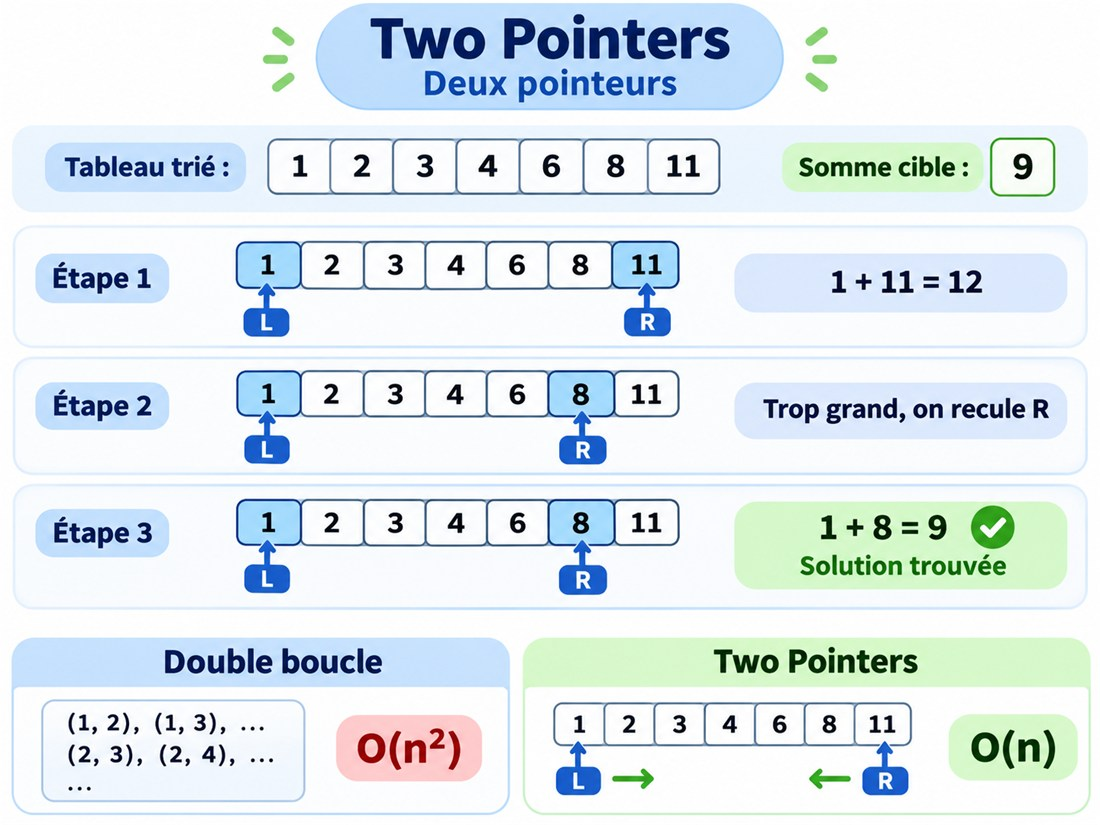

Sur l'image, un autre exemple : `[1, 2, 3, 4, 6, 8, 11]`, cible 9. `L` (gauche) et `R` (droite) partent des deux bouts. 1 + 11 = 12 est trop grand → `R` recule sur 8 ; 1 + 8 = 9 → trouvé. Deux sommes calculées, là où la double boucle aurait testé les paires une par une.

Ça ne marche **que parce que la liste est triée** : c'est ce qui garantit qu'avancer `gauche` augmente la somme et que reculer `droite` la diminue.

**Pourquoi on ne rate aucune solution ?** Si `nombres[gauche] + nombres[droite]` est trop petit, alors `nombres[gauche]` + n'importe quel autre élément restant (tous ≤ `nombres[droite]`) est aussi trop petit. `nombres[gauche]` ne peut faire partie d'aucune solution : on peut l'abandonner sans regret. Même raisonnement de l'autre côté.

**Trace à la main** (cible = 10) :

| `gauche` | `droite` | valeurs | somme | décision |
|---|---|---|---|---|
| 0 | 5 | 1 + 11 | 12 | trop grand → `droite` recule |
| 0 | 4 | 1 + 8 | 9 | trop petit → `gauche` avance |
| 1 | 4 | 3 + 8 | 11 | trop grand → `droite` recule |
| 1 | 3 | 3 + 6 | 9 | trop petit → `gauche` avance |
| 2 | 3 | 4 + 6 | 10 | **trouvé** |

In [ ]:
def paire_triee(nombres, cible):
    gauche, droite = 0, len(nombres) - 1
    while gauche < droite:                 # on s'arrête quand ils se rejoignent
        somme = nombres[gauche] + nombres[droite]
        if somme == cible:
            return (gauche, droite)
        elif somme < cible:
            gauche += 1                    # besoin de plus grand
        else:
            droite -= 1                    # besoin de plus petit
    return None

print(paire_triee([1, 3, 4, 6, 8, 11], 10))    # (2, 3)
print(paire_triee([1, 3, 4, 6, 8, 11], 100))   # None

À chaque tour, un pointeur avance d'une case vers l'autre : au plus n tours → **O(n)**, sans mémoire supplémentaire.
Autre usage classique : vérifier un **palindrome** (`gauche` et `droite` comparent les lettres en se rapprochant).

### Fenêtre glissante ou deux pointeurs ?
| | Fenêtre glissante | Deux pointeurs opposés |
|---|---|---|
| Où partent les deux indices | tous les deux à gauche | un à chaque bout |
| Comment ils bougent | dans le même sens (→ →) | l'un vers l'autre (→ ←) |
| Ce qu'on cherche | la meilleure **portion contiguë** | une **paire** dans une liste **triée**, un palindrome |

## Quand y penser ?
- « sous-tableau », « sous-chaîne », « consécutifs », « contigu », « fenêtre de taille k » → **fenêtre glissante** ;
- « la plus longue / la plus courte portion telle que… », « au plus k … » → **fenêtre de taille variable** ;
- « liste triée » + « paire » / « deux éléments dont la somme… » → **deux pointeurs** ;
- « palindrome », « inverser sur place » → **deux pointeurs**.

## Les pièges
- Longueur = `fin - debut + 1`, pas `fin - debut`.
- `debut` ne doit **jamais reculer** (cf. `"abba"`).
- La fenêtre ne marche que pour du **contigu** : si l'énoncé autorise à sauter des éléments, c'est un autre problème.
- Les deux pointeurs exigent une liste **triée**. Trier soi-même coûte O(n log n) **et fait perdre les positions d'origine** : si l'énoncé demande les positions d'origine, utilise plutôt le set/dict du thème 1.

## À toi de jouer — voyelles dans une fenêtre
> Écris `max_voyelles(texte, k)` qui renvoie le nombre maximum de voyelles (`a e i o u`) dans une sous-chaîne de longueur exactement `k`. Si `k` est plus grand que le texte, renvoie 0.
> `max_voyelles("abciiidef", 3)` → 3 (`"iii"`).

**Indice** : c'est une fenêtre de taille **fixe**. Au lieu d'une somme, tiens un **compteur de voyelles** : +1 si le caractère qui entre est une voyelle, −1 si celui qui sort en est une.

In [ ]:
def max_voyelles(texte, k):
    # À toi de jouer !
    pass

verifier(max_voyelles, [
    (("abciiidef", 3), 3),
    (("aeiou", 2), 2),
    (("leetcode", 3), 2),
    (("rythm", 2), 0),
    (("ab", 3), 0),
])

<details>
<summary><b>Voir la solution</b> (essaie vraiment d'abord !)</summary>

```python
def max_voyelles(texte, k):
    if k > len(texte):
        return 0
    voyelles = set("aeiou")

    compte = 0
    for c in texte[:k]:                 # la première fenêtre
        if c in voyelles:
            compte += 1
    meilleur = compte

    for fin in range(k, len(texte)):
        if texte[fin] in voyelles:      # le caractère qui entre
            compte += 1
        if texte[fin - k] in voyelles:  # le caractère qui sort
            compte -= 1
        meilleur = max(meilleur, compte)
    return meilleur
```

</details>

---

**Suite :** [Thème 4 — La pile (stack)](theme4_pile.ipynb) ➡ · [Retour au sommaire](00_sommaire.ipynb)

**S'entraîner :** [Série 3 — Deux pointeurs et fenêtre glissante](exercices/serie3_deux_pointeurs_fenetre.ipynb) (6 exercices avec tests automatiques)